# Jupyter Notebook for the 1st lab session
Practice on the **Pandas data analysis library**

In [159]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

## Part 1
Simple data exploration task on the **New York Point Of Interest** dataset
exploiting the Pandas library.

In [160]:
pois = pd.read_csv("../Data/NYC_POIs/pois_all_info", sep="\t")
ids = pd.read_csv("../Data/NYC_POIs/ny_municipality_pois_id.csv", header=None).squeeze("columns")

/var/folders/31/dy_p77hd38b2szb8fxvx7pfh0000gn/T/ipykernel_59595/2254257333.py:1: DtypeWarning: Columns (4: amenity, 5: name, 6: shop, 7: public_transport, 8: highway) have mixed types. Specify dtype option on import or set low_memory=False.
  pois = pd.read_csv("../Data/NYC_POIs/pois_all_info", sep="\t")


### Load the New York Point Of Interest dataset exploiting Pandas APIs. Load the NY Municipality POIs ID metadata as well and filter out from the New York Point Of Interest data the records that do not belong to the New York municipality.
• Which columns have been parsed?
• Which is the type of the data inferred by Pandas?

In [161]:
pois

,@id,@type,@lat,@lon,amenity,name,shop,public_transport,highway
0,42432939,node,40.814104,-73.949623,NaN,NaN,NaN,stop_position,NaN
1,42448838,node,40.761647,-73.949864,NaN,NaN,NaN,stop_position,NaN
2,42723103,node,40.852182,-73.772677,ferry_terminal,Hart Island Ferry Terminal,NaN,NaN,NaN
3,42764076,node,40.867164,-73.882158,NaN,Botanical Garden,NaN,stop_position,NaN
4,42811266,node,40.704806,-73.772734,NaN,NaN,NaN,stop_position,NaN
...,...,...,...,...,...,...,...,...,...
77879,600919896,way,NaN,NaN,NaN,NaN,NaN,NaN,NaN
77880,600919898,way,NaN,NaN,NaN,NaN,NaN,NaN,NaN
77881,600919900,way,NaN,NaN,NaN,NaN,NaN,NaN,NaN
77882,600931232,way,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [162]:
ids

0          42432939
1          42448838
2          42723103
3          42764076
4          42811266
            ...    
53525    2553096114
53526    2553096138
53527    2553096143
53528    2553096154
53529    6146672068
Name: 0, Length: 53530, dtype: int64

In [163]:
filtered_pois = pois[pois["@id"].isin(ids)]
filtered_pois

,@id,@type,@lat,@lon,amenity,name,shop,public_transport,highway
0,42432939,node,40.814104,-73.949623,NaN,NaN,NaN,stop_position,NaN
1,42448838,node,40.761647,-73.949864,NaN,NaN,NaN,stop_position,NaN
2,42723103,node,40.852182,-73.772677,ferry_terminal,Hart Island Ferry Terminal,NaN,NaN,NaN
3,42764076,node,40.867164,-73.882158,NaN,Botanical Garden,NaN,stop_position,NaN
4,42811266,node,40.704806,-73.772734,NaN,NaN,NaN,stop_position,NaN
...,...,...,...,...,...,...,...,...,...
76980,2553096114,node,40.736006,-73.713202,NaN,NaN,NaN,NaN,NaN
76981,2553096138,node,40.736020,-73.713063,NaN,NaN,NaN,NaN,NaN
76982,2553096143,node,40.736024,-73.713047,NaN,NaN,NaN,NaN,NaN
76983,2553096154,node,40.736030,-73.713089,NaN,NaN,NaN,NaN,NaN


### For each column in the loaded dataset count the number of missing values.
* What did you expect?
* What can you infer from this first analysis?

In [164]:
filtered_pois["@id"].nunique()

53515

In [165]:
filtered_pois.info()

<class 'pandas.DataFrame'>
Index: 53521 entries, 0 to 76984
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   @id               53521 non-null  int64  
 1   @type             53521 non-null  str    
 2   @lat              53521 non-null  float64
 3   @lon              53521 non-null  float64
 4   amenity           24697 non-null  str    
 5   name              30549 non-null  str    
 6   shop              8717 non-null   str    
 7   public_transport  8375 non-null   str    
 8   highway           7559 non-null   str    
dtypes: float64(2), int64(1), str(6)
memory usage: 4.1 MB


In [166]:
ids.info()

<class 'pandas.Series'>
RangeIndex: 53530 entries, 0 to 53529
Series name: 0
Non-Null Count  Dtype
--------------  -----
53530 non-null  int64
dtypes: int64(1)
memory usage: 418.3 KB


In [167]:
print("Missing values in:")
for col in filtered_pois.columns:
    print(f"- {col}: {filtered_pois[col].isna().sum()}")

Missing values in:
- @id: 0
- @type: 0
- @lat: 0
- @lon: 0
- amenity: 28824
- name: 22972
- shop: 44804
- public_transport: 45146
- highway: 45962


Since many columns contain missing values, I suppose that each record represents a specific Point of Interest (POI), identified by its coordinates and described by a set of attributes indicating its type or characteristics.

Therefore, missing values may not necessarily indicate incomplete data, but rather attributes that are not applicable to a particular POI. For instance, a restaurant would typically have a value in the `amenity` column, but not in the `highway` column.

In [168]:
cols = ["amenity", "shop", "highway", "public_transport"]
filtered_pois[
    cols
].notna().sum(axis=1).value_counts()

1    37306
0    10194
2     6021
Name: count, dtype: int64

In [169]:
filtered_pois.loc[
    filtered_pois[cols].notna().sum(axis=1) == 2,
    cols
].head(10)

,amenity,shop,highway,public_transport
3571,cafe,books,NaN,NaN
5358,NaN,NaN,bus_stop,platform
5817,NaN,NaN,bus_stop,platform
8132,NaN,NaN,bus_stop,platform
8134,NaN,NaN,bus_stop,platform
8141,NaN,NaN,bus_stop,platform
8142,NaN,NaN,bus_stop,platform
8143,NaN,NaN,bus_stop,platform
8146,NaN,NaN,bus_stop,platform
8170,NaN,NaN,bus_stop,platform


From the last two analysis, I can say that the attributes are **not mutually exclusive**, but, in the entire dataset, there are records that contain 2 attributes with a setted value at the same time

### Now, analyze the distribution of the POI types for each POI category. 
Point of interest categories are amenity, shop, public_transport and highway. For each of them, plot a histogram showing the distribution of the types of POI. Note that, for certain categories, due to the high number of types,bars and labels could not fit adequately in the figure. Hence, fix a threshold (a percentage one is better) and plot only the most frequent types.
To simplify the subsequent analysis, use the retained top frequent POI types also for the following exercises.

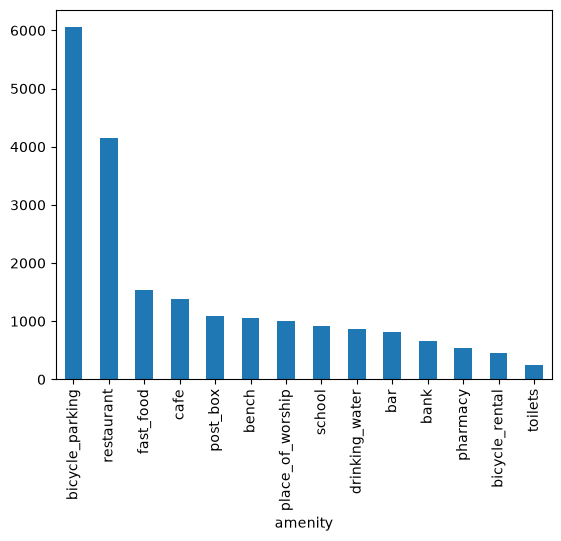

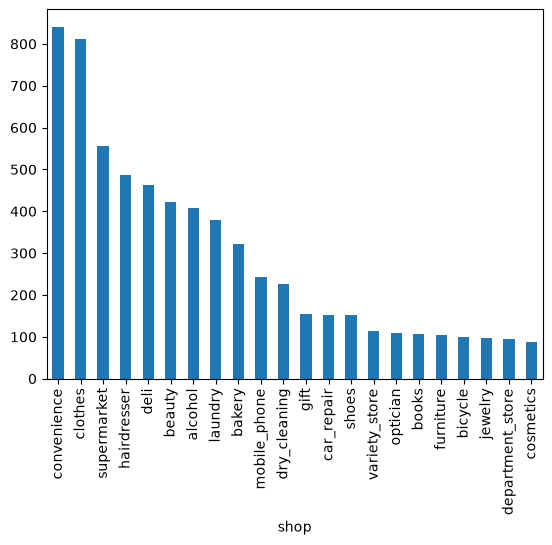

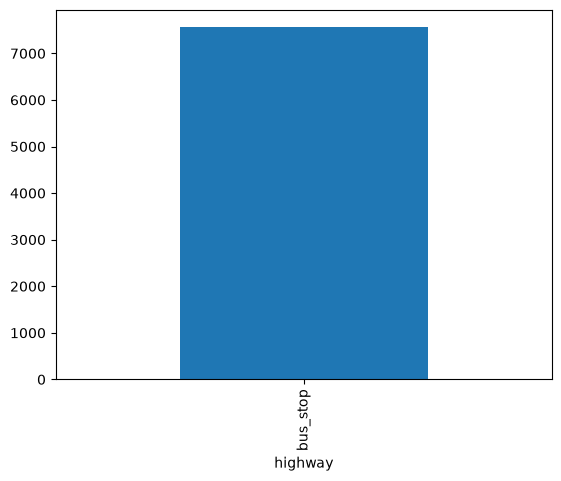

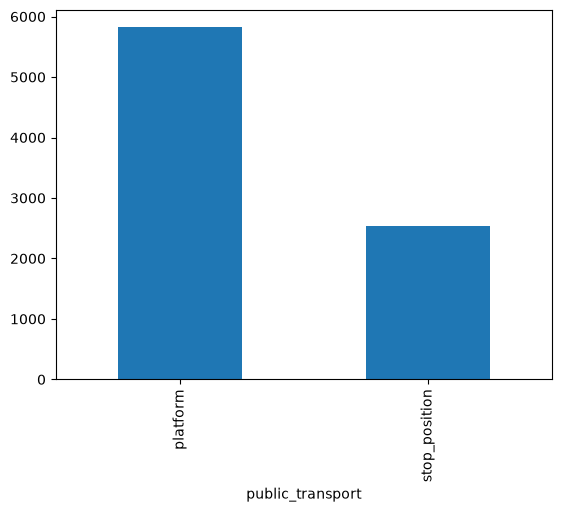

In [170]:
most_freq_types = {}

for cat in categories:  # distribution of the types for each category WITH filtering
    norm_val_count = filtered_pois[cat].value_counts(normalize=True)
    tresh_val_count_index = norm_val_count[norm_val_count >= 0.01].index    #filter according to the normalized percentage

    most_freq_types[cat] = tresh_val_count_index

    filtered_pois[cat].value_counts()[tresh_val_count_index].plot.bar()

    plt.show()

In [171]:
most_freq_types

{'amenity': Index(['bicycle_parking', 'restaurant', 'fast_food', 'cafe', 'post_box',
        'bench', 'place_of_worship', 'school', 'drinking_water', 'bar', 'bank',
        'pharmacy', 'bicycle_rental', 'toilets'],
       dtype='str', name='amenity'),
 'shop': Index(['convenience', 'clothes', 'supermarket', 'hairdresser', 'deli',
        'beauty', 'alcohol', 'laundry', 'bakery', 'mobile_phone',
        'dry_cleaning', 'gift', 'car_repair', 'shoes', 'variety_store',
        'optician', 'books', 'furniture', 'bicycle', 'jewelry',
        'department_store', 'cosmetics'],
       dtype='str', name='shop'),
 'highway': Index(['bus_stop'], dtype='str', name='highway'),
 'public_transport': Index(['platform', 'stop_position'], dtype='str', name='public_transport')}

### Show the points of interest on the New York map for a given category (e.g. amenity). 
To do so, you have to define a new function (or a new class) that, given the name of the POI category is able to show a scatter plot of the locations of the POI types, onto the New York municipality map, with a different color for each category.
* Are you able to identify areas in which the concentration of a specific POI type is higher then
others?
* How can you better characterize the POI distributions?

In [172]:
im = np.array(Image.open("../Data/NYC_POIs/New_York_City_Map.PNG"))
H, W = im.shape[:2]

In [173]:
min_lat = filtered_pois["@lat"].min()
max_lat = filtered_pois["@lat"].max()

min_lon = filtered_pois["@lon"].min()
max_lon = filtered_pois["@lon"].max()

coords_norm = pd.DataFrame()

coords_norm["@lat"] = (filtered_pois["@lat"] - min_lat) / (max_lat - min_lat)
coords_norm["@lon"] = (filtered_pois["@lon"] - min_lon) / (max_lon - min_lon)

coords_norm

coords_norm["@lat_im"] = (1-coords_norm["@lat"]) * H
coords_norm["@lon_im"] = coords_norm["@lon"] * W



In [174]:
def plotPOI(category):
    colors = plt.get_cmap("tab20", len(most_freq_types[category]))
    im = np.array(Image.open("../Data/NYC_POIs/New_York_City_Map.PNG"))
    fig, ax = plt.subplots(figsize=(12, 10))

    ax.imshow(im)

    for i,poi_type in enumerate(most_freq_types[category]):
        mask = filtered_pois[category] == poi_type
        ax.scatter(
            coords_norm.loc[mask, "@lon_im"],
            coords_norm.loc[mask, "@lat_im"],
            color=colors(i),
            label=poi_type,
            s=3,
            alpha=0.6
        )


    ax.legend(
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
        markerscale=3
    )    

    ax.set_title(f"NYC POIs - {category}")
    ax.set_xlim(0, im.shape[1])
    ax.set_ylim(im.shape[0], 0)
    
    plt.show()

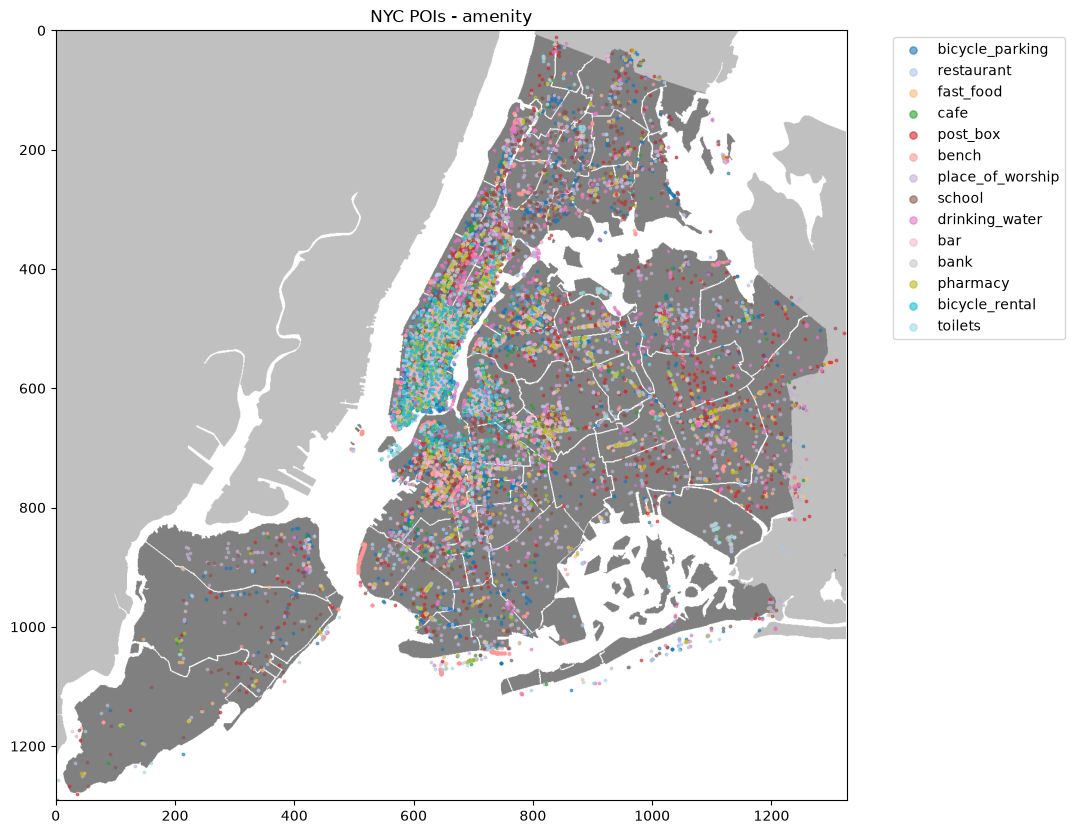

In [175]:
plotPOI("amenity")

### Discretize the POIs by geographical position. 
Define a new function (or class) that is able to split the
geographical position of the POIs using a grid. Once defined the grid over the New York municipality,
the function has to assign each POI to the cell to which it belongs to. The result should be a Pandas
DataFrame with a new column containing the cell_id for each POI.

In [176]:
N_SPLITS = 20
y = np.floor((filtered_pois["@lat"] - min_lat) / (max_lat - min_lat) * N_SPLITS)
x = np.floor((filtered_pois["@lon"] - min_lon) / (max_lon - min_lon) * N_SPLITS)

filtered_pois["cell_id"] = (
    y.clip(0, N_SPLITS-1).astype(int) * N_SPLITS + 
    x.clip(0, N_SPLITS-1).astype(int)
)
display(filtered_pois[["@lat", "@lon", "cell_id"]].head())

,@lat,@lon,cell_id
0,40.814104,-73.949623,310
1,40.761647,-73.949864,250
2,40.852182,-73.772677,337
3,40.867164,-73.882158,353
4,40.704806,-73.772734,197


### Now you have to identify how many times a POI type is contained in each cell, for each category.
Create a new DataFrame containing the cell_id as index, the POI types as columns and the count of the occurrences of each type, in each cell, as values.

In [180]:
occ = pd.DataFrame()
for cat in categories:
    counts = filtered_pois.groupby(["cell_id", cat]).size()
    counts = counts.unstack(fill_value=0)
    counts = counts.reindex(
        index=range(N_SPLITS**2),
        columns=most_freq_types[cat],
        fill_value=0
    )
    occ = pd.concat([occ, counts], axis = 1)

pairs = []

for cat, types in most_freq_types.items():
    for poi_type in types:
        pairs.append((cat, poi_type))

occ.columns = pd.MultiIndex.from_tuples(
        pairs
    )

In [181]:
occ

amenity                                           \
        bicycle_parking restaurant fast_food cafe post_box bench   
cell_id                                                            
0                     1          2         1    0        2     0   
1                     0          0         0    1        0     0   
2                     0          0         0    0        0     0   
3                     0          0         0    0        0     0   
4                     0          0         0    0        0     0   
...                 ...        ...       ...  ...      ...   ...   
395                   0          0         0    0        0     0   
396                   0          0         0    0        0     0   
397                   0          0         0    0        0     0   
398                   0          0         0    0        0     0   
399                   0          0         0    0        0     0   

                                                    ...     shop        \
        place_of_worship school drinking_water bar  ... optician books   
cell_id                                             ...                  
0                      1      2              1   0  ...        0     0   
1                      0      1              0   0  ...        0     0   
2                      1      0              0   0  ...        0     0   
3                      0      0              0   0  ...        0     0   
4                      0      0              0   0  ...        0     0   
...                  ...    ...            ...  ..  ...      ...   ...   
395                    0      0              0   0  ...        0     0   
396                    0      0              0   0  ...        0     0   
397                    0      0              0   0  ...        0     0   
398                    0      0              0   0  ...        0     0   
399                    0      0              0   0  ...        0     0   

                                                              highway  \
        furniture bicycle jewelry department_store cosmetics bus_stop   
cell_id                                                                 
0               0       0       0                0         0        8   
1               0       0       0                0         0        0   
2               0       0       0                0         0        0   
3               0       0       0                0         0        0   
4               0       0       0                0         0        0   
...           ...     ...     ...              ...       ...      ...   
395             0       0       0                0         0        0   
396             0       0       0                0         0        0   
397             0       0       0                0         0        0   
398             0       0       0                0         0        0   
399             0       0       0                0         0        0   

        public_transport                
                platform stop_position  
cell_id                                 
0                      6             2  
1                      0             0  
2                      0             0  
3                      0             0  
4                      0             0  
...                  ...           ...  
395                    0             0  
396                    0             0  
397                    0             0  
398                    0             0  
399                    0             0  

[400 rows x 39 columns]

### For the categories amenities and shop identify if there exist a correlation between the location of different POI types. Compute the pairwise correlation between the columns of the cell-type DataFrame and show it through a heatmap chart.
* Are you able to identify which are the POI types more correlated between each other? What
does it mean?
* Which are the more correlated tuples? Do they belong to the same category?

In [186]:
occ["amenity"].info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   bicycle_parking   400 non-null    int64
 1   restaurant        400 non-null    int64
 2   fast_food         400 non-null    int64
 3   cafe              400 non-null    int64
 4   post_box          400 non-null    int64
 5   bench             400 non-null    int64
 6   place_of_worship  400 non-null    int64
 7   school            400 non-null    int64
 8   drinking_water    400 non-null    int64
 9   bar               400 non-null    int64
 10  bank              400 non-null    int64
 11  pharmacy          400 non-null    int64
 12  bicycle_rental    400 non-null    int64
 13  toilets           400 non-null    int64
dtypes: int64(14)
memory usage: 43.9 KB


In [187]:
occ["shop"].describe()

type,convenience,clothes,supermarket,hairdresser,deli,beauty,alcohol,laundry,bakery,mobile_phone,...,car_repair,shoes,variety_store,optician,books,furniture,bicycle,jewelry,department_store,cosmetics
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,...,400.000000,400.000000,400.000000,400.000000,400.00000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,2.102500,2.027500,1.387500,1.217500,1.155000,1.055000,1.020000,0.950000,0.805000,0.610000,...,0.382500,0.380000,0.282500,0.275000,0.26750,0.262500,0.247500,0.242500,0.235000,0.220000
std,7.915088,11.542522,3.746657,5.348056,3.200247,4.630397,3.387224,2.979041,2.971371,2.100937,...,1.622583,2.159226,0.924571,1.405102,1.28455,1.259985,0.963621,1.325929,1.094427,1.296457
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
max,82.000000,161.000000,34.000000,63.000000,23.000000,65.000000,31.000000,27.000000,32.000000,18.000000,...,18.000000,24.000000,8.000000,18.000000,15.00000,17.000000,9.000000,15.000000,13.000000,14.000000


In [189]:
occ["shop", "clothes"].idxmax() #cell ID with the highest number of POIs of type "clothes"

209

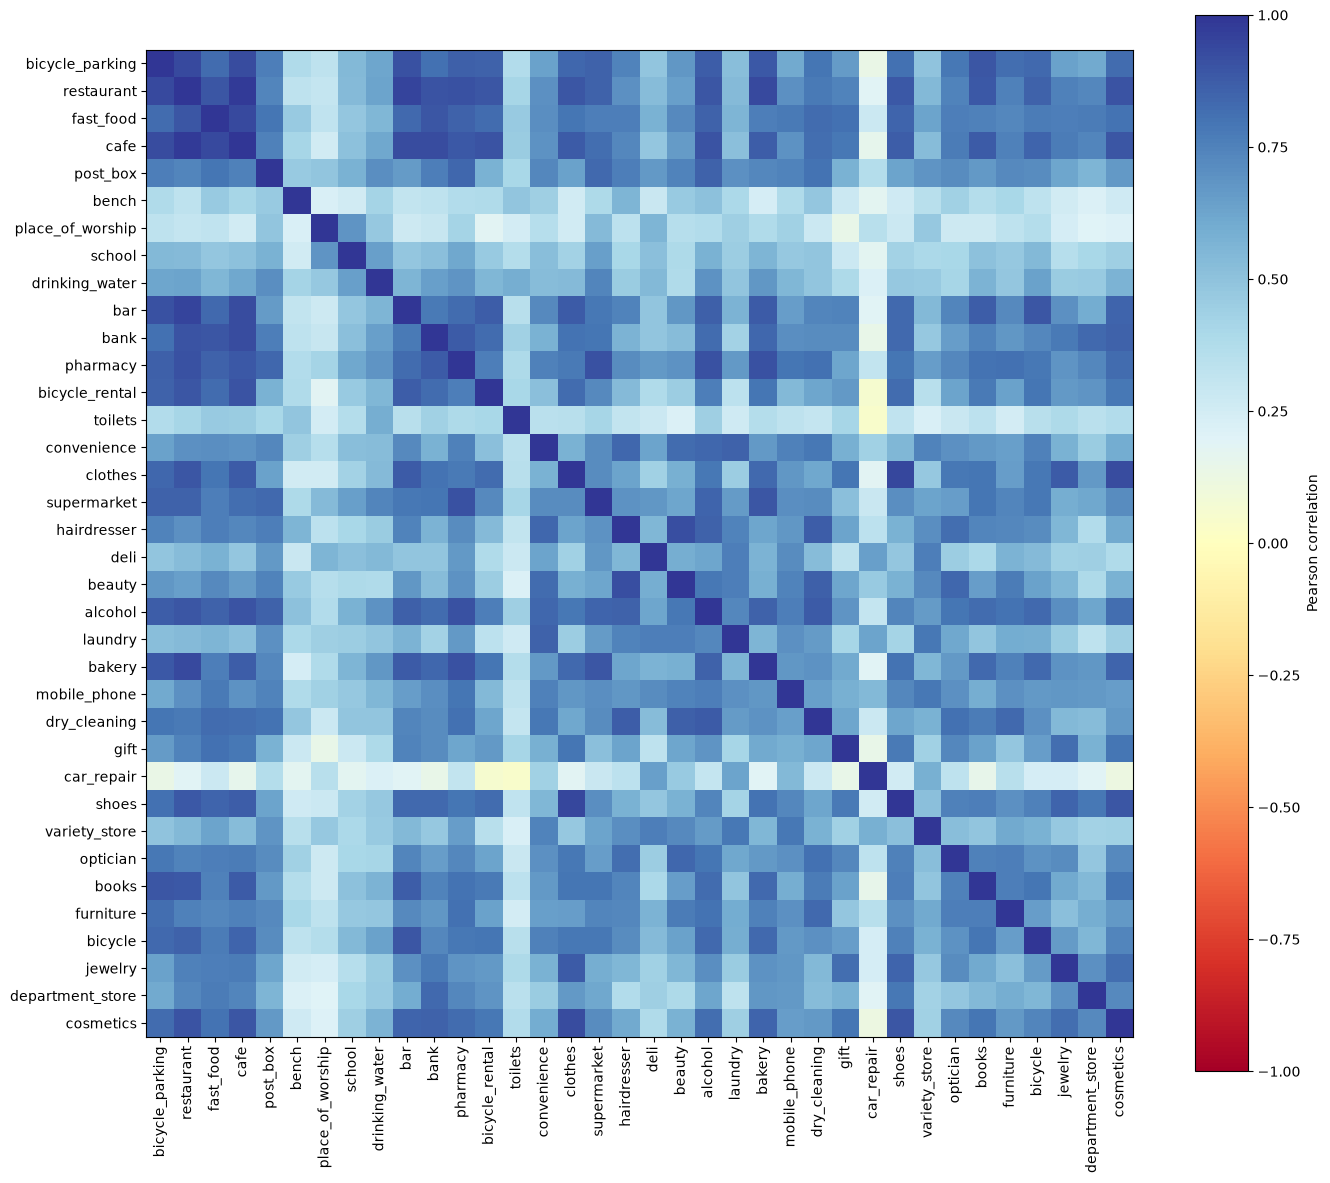

In [198]:
corr_map = occ[["amenity", "shop"]].corr()

plt.figure(figsize=(14, 12))
plt.imshow(corr_map, cmap="RdYlBu", vmin=-1, vmax=1)

labels = corr_map.columns.get_level_values("type")

plt.xticks(
    ticks=range(len(labels)),
    labels=labels,
    rotation=90
)

plt.yticks(
    ticks=range(len(labels)),
    labels=labels
)

plt.colorbar(label="Pearson correlation")
plt.tight_layout()
plt.show()

In [204]:
corr_map.loc[
    ("amenity", "restaurant"),
    ("amenity", "cafe")
]

np.float64(0.9771289923264778)

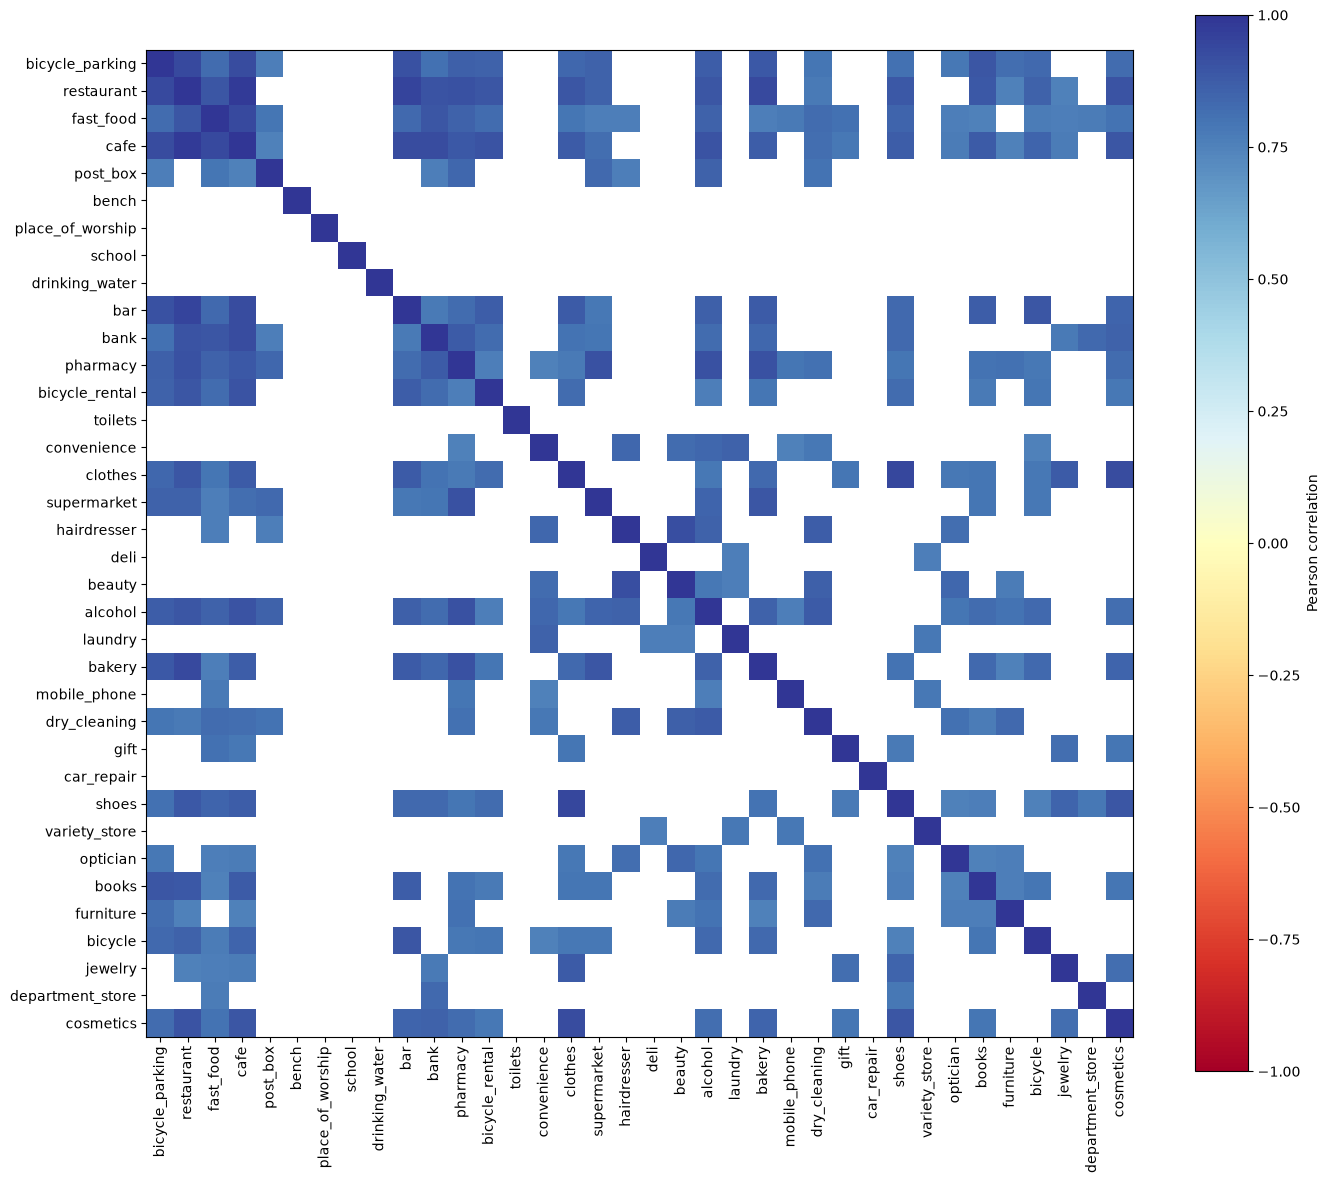

In [206]:
corr_map = occ[["amenity", "shop"]].corr()

plt.figure(figsize=(14, 12))
plt.imshow(corr_map[corr_map > 0.75], cmap="RdYlBu", vmin=-1, vmax=1)

labels = corr_map.columns.get_level_values("type")

plt.xticks(
    ticks=range(len(labels)),
    labels=labels,
    rotation=90
)

plt.yticks(
    ticks=range(len(labels)),
    labels=labels
)

plt.colorbar(label="Pearson correlation")
plt.tight_layout()
plt.show()

category  type             category  type      
amenity   restaurant       amenity   cafe          0.977129
                                     bar           0.952924
shop      clothes          shop      shoes         0.940526
amenity   restaurant       shop      bakery        0.934591
          bicycle_parking  amenity   restaurant    0.933327
          fast_food        amenity   cafe          0.931877
          cafe             amenity   bar           0.928265
shop      clothes          shop      cosmetics     0.927612
amenity   cafe             amenity   bank          0.922640
          bicycle_parking  amenity   cafe          0.922268
dtype: float64